In [221]:
import pandas as pd

In [222]:
df = pd.read_csv("../data/H2.csv")

In [223]:
df = df.drop_duplicates() # TODO to be discussed


In [224]:
print(df.shape)

(53428, 31)


In [225]:
y_cancel = df["IsCanceled"].copy() #we need it later when we use profile the clusters eg. cluster2 cancel 70%

drop_col= ["IsCanceled", "ReservationStatus", "ReservationStatusDate",
"AssignedRoomType","ArrivalDateYear", "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth"] #TODO swap week number with month
x = df.drop(columns = drop_col)


In [226]:
print(x.shape)
print(x.isna().sum())                   


(53428, 24)
LeadTime                       0
ArrivalDateMonth               0
StaysInWeekendNights           0
StaysInWeekNights              0
Adults                         0
Children                       4
Babies                         0
Meal                           0
Country                        6
MarketSegment                  0
DistributionChannel            0
IsRepeatedGuest                0
PreviousCancellations          0
PreviousBookingsNotCanceled    0
ReservedRoomType               0
BookingChanges                 0
DepositType                    0
Agent                          0
Company                        0
DaysInWaitingList              0
CustomerType                   0
ADR                            0
RequiredCarParkingSpaces       0
TotalOfSpecialRequests         0
dtype: int64


In [227]:
print((x == "       NULL").sum()) 

LeadTime                           0
ArrivalDateMonth                   0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           0
Babies                             0
Meal                               0
Country                            0
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           5587
Company                        50646
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
RequiredCarParkingSpaces           0
TotalOfSpecialRequests             0
dtype: int64


In [228]:
import numpy as np

obj_cols = x.select_dtypes(include="object").columns
x[obj_cols] = x[obj_cols].apply(lambda c: c.str.strip())
x = x.replace("NULL", np.nan)

print(x.isna().sum()[lambda s: s > 0])

Children        4
Country         6
Agent        5587
Company     50646
dtype: int64


C:\Users\lap store\AppData\Local\Temp\ipykernel_42308\431480390.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = x.select_dtypes(include="object").columns


In [229]:
x = x.drop(columns=["Company", "Agent"])
x["Children"] = x["Children"].fillna(0)


In [230]:
country = x["Country"]
country = country.fillna("Unknown")
top = country.value_counts().head(8).index
country = country.where(country.isin(top), "Other")

print(country.value_counts())

x["Country"] = country         #   if you want to save as feature then encode later #TODO

Country
Other    14096
PRT      13215
FRA       7412
GBR       4528
DEU       4467
ESP       3784
ITA       2647
BEL       1690
BRA       1589
Name: count, dtype: int64


In [231]:
print(x.duplicated().sum()) #was 27131 and 25902 in df so it got inflated so ill drop it up top
print((x["ADR"] <= 0).sum())
print((x["Adults"] == 0).sum())
print(((x["StaysInWeekendNights"] + x["StaysInWeekNights"]) == 0).sum())

1510
1077
373
288


In [232]:
nights = x["StaysInWeekendNights"] + x["StaysInWeekNights"]
bad = (x["ADR"] <= 0) | (x["Adults"] == 0) | (nights == 0)
print(bad.sum())

x = x[~bad]
y_cancel = y_cancel.loc[x.index]

1320


In [233]:
print(df.duplicated().sum())
print(x.shape, y_cancel.shape)
print(x.isna().sum().sum())


0
(52108, 22) (52108,)
0


In [234]:
x = x[x["ADR"] < 1000]
y_cancel = y_cancel.loc[x.index]
print(x["ADR"].skew())

1.0917610053485651


LeadTime                       -0.795478
Adults                         -0.107361
StaysInWeekendNights            0.944614
TotalOfSpecialRequests          1.045239
ADR                             1.091761
StaysInWeekNights               2.396686
Children                        3.574742
RequiredCarParkingSpaces        5.130138
BookingChanges                  5.762711
IsRepeatedGuest                 5.983195
DaysInWaitingList              17.186737
PreviousBookingsNotCanceled    21.196069
PreviousCancellations          24.443477
Babies                         38.137689
dtype: float64


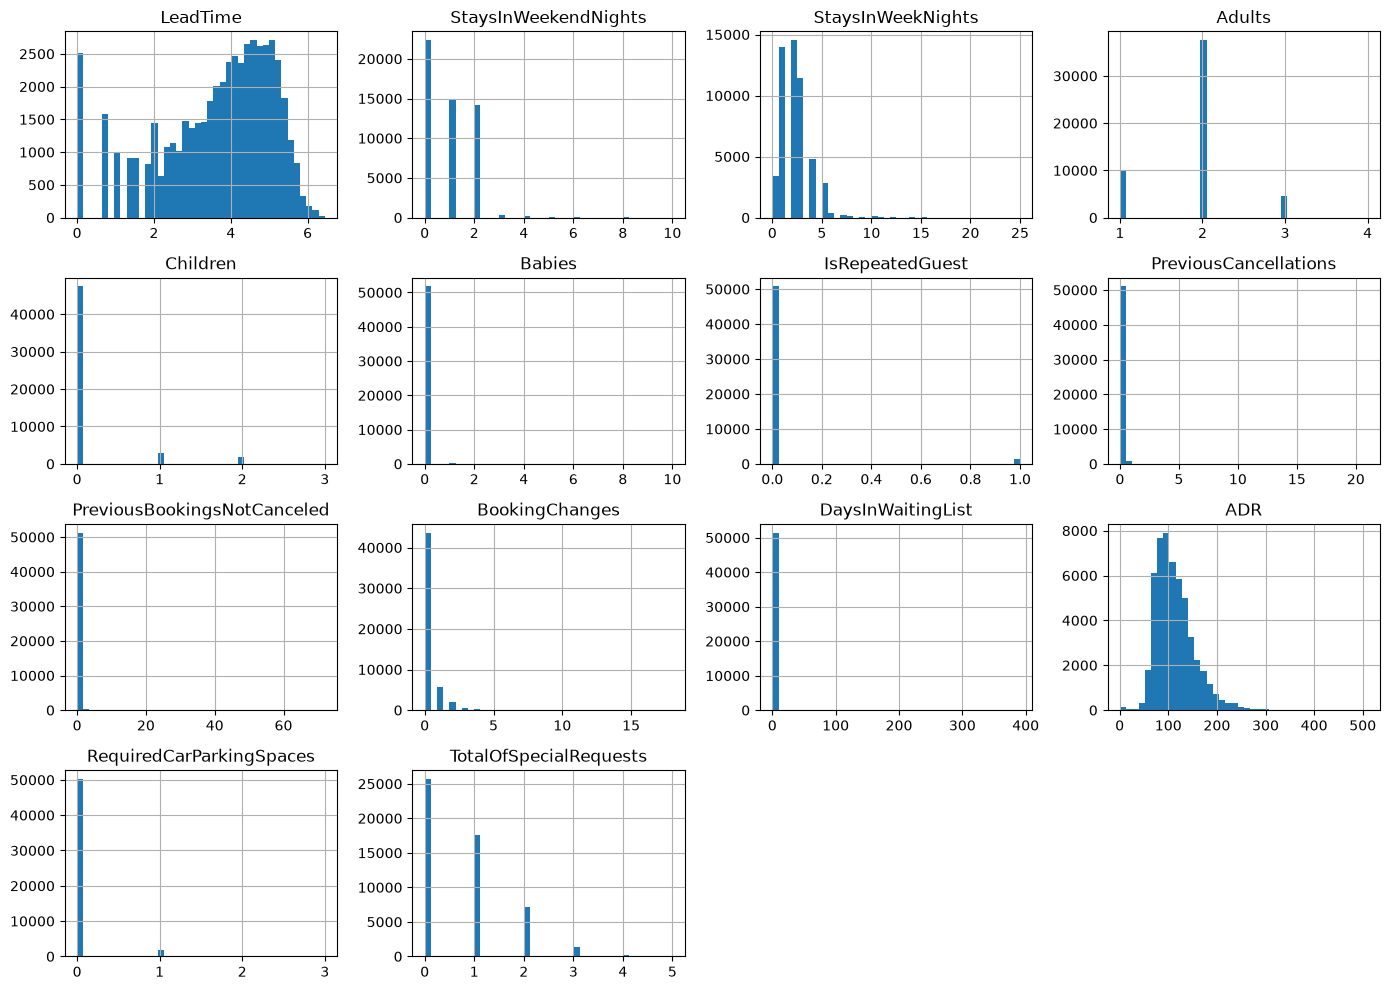

In [ ]:
import matplotlib.pyplot as plt
x["LeadTime"] = np.log1p(x["LeadTime"]) #log(1+x) #TODO for the rest
num = x.select_dtypes("number")
print(num.skew().sort_values())

num.hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

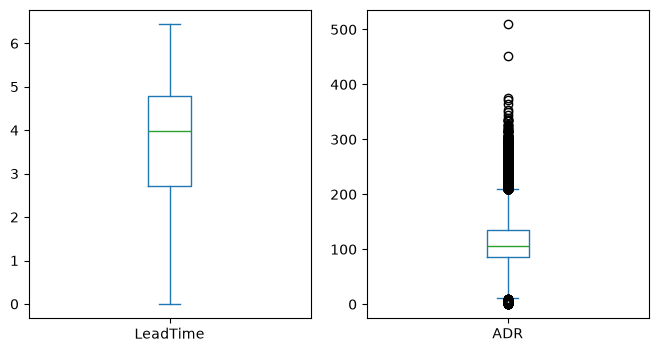

In [236]:
x[["LeadTime", "ADR"]].plot(kind="box", subplots=True, figsize=(8, 4))
plt.show()

In [237]:
print(df.loc[df["ADR"] <= 0, "MarketSegment"].value_counts())

MarketSegment
Complementary    479
Offline TA/TO    170
Online TA        167
Groups           122
Direct           107
Corporate         27
Aviation           5
Name: count, dtype: int64
